# Example 4: Classification

## Regression formulation

Let's first treat the problem as a regression problem (output dimension = 1, MSE loss). 

create the two moon dataset

cuda


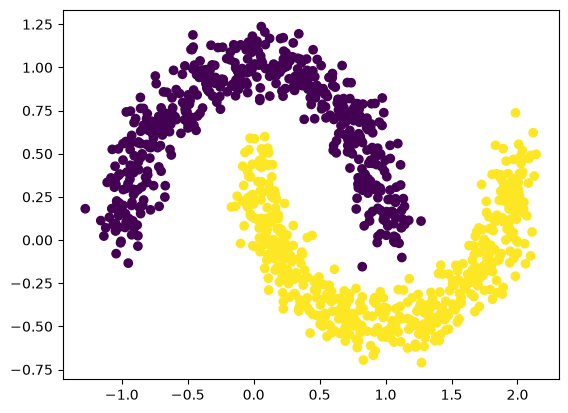

In [1]:
import torch
from xkan import KANNetwork, fit
from xkan.symbolic import auto_symbolic, symbolic_formula
from xkan.utils import ex_round
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

train_input, train_label = make_moons(n_samples=1000, shuffle=True, noise=0.1, random_state=None)
test_input, test_label = make_moons(n_samples=1000, shuffle=True, noise=0.1, random_state=None)

# training and test sets: inputs under 'x', labels under 'y'
dtype = torch.get_default_dtype()
train = {'x': torch.from_numpy(train_input).type(dtype).to(device),
         'y': torch.from_numpy(train_label[:,None]).type(dtype).to(device)}
test = {'x': torch.from_numpy(test_input).type(dtype).to(device),
        'y': torch.from_numpy(test_label[:,None]).type(dtype).to(device)}

X = train['x']
y = train['y']
plt.scatter(X[:,0].cpu().detach().numpy(), X[:,1].cpu().detach().numpy(), c=y[:,0].cpu().detach().numpy())

Train KAN

In [2]:
model = KANNetwork([2, 1], grid=3, k=3, device=device)

def train_acc():
    return torch.mean((torch.round(model(train['x'])[:,0]) == train['y'][:,0]).type(dtype))

def test_acc():
    return torch.mean((torch.round(model(test['x'])[:,0]) == test['y'][:,0]).type(dtype))

history = fit(model, train, test, steps=20)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)
train_acc().item(), test_acc().item()

train RMSE 0.15235388550909992 test RMSE 0.15677776611773078


(1.0, 0.9970000386238098)

Automatic symbolic regression

In [3]:
lib = ['x','x^2','x^3','x^4','exp','log','sqrt','tanh','sin','tan','abs']
auto_symbolic(model, train['x'], lib=lib)
formula = symbolic_formula(model)[0][0]
ex_round(formula, 4)

fixing (0,0,0) with sin, r2=0.9739394783973694, c=2
fixing (0,1,0) with x, r2=0.9653955101966858, c=1


-0.8424*x_2 + 0.3888*sin(3.1971*x_1 + 7.791) + 0.7124

How accurate is this formula?

In [4]:
# how accurate is this formula?
def acc(formula, X, y):
    batch = X.shape[0]
    correct = 0
    for i in range(batch):
        correct += np.round(np.array(formula.subs('x_1', X[i,0]).subs('x_2', X[i,1])).astype(np.float64)) == y[i,0]
    return correct/batch

print('train acc of the formula:', acc(formula, train['x'], train['y']))
print('test acc of the formula:', acc(formula, test['x'], test['y']))

train acc of the formula: tensor(0.9980, device='cuda:0')


test acc of the formula: tensor(0.9980, device='cuda:0')


## Classification formulation

Let's then treat the problem as a classification problem (output dimension = 2, CrossEntropy loss). 

Create the two moon datatset

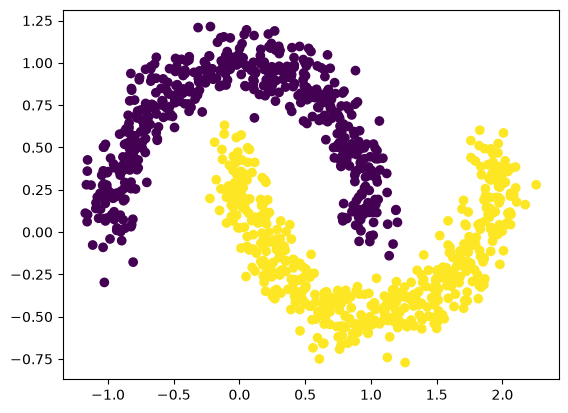

In [5]:
from xkan import KANNetwork
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import torch
import numpy as np

train_input, train_label = make_moons(n_samples=1000, shuffle=True, noise=0.1, random_state=None)
test_input, test_label = make_moons(n_samples=1000, shuffle=True, noise=0.1, random_state=None)

# integer class labels under 'y'
train = {'x': torch.from_numpy(train_input).type(dtype).to(device),
         'y': torch.from_numpy(train_label).type(torch.long).to(device)}
test = {'x': torch.from_numpy(test_input).type(dtype).to(device),
        'y': torch.from_numpy(test_label).type(torch.long).to(device)}

X = train['x']
y = train['y']
plt.scatter(X[:,0].cpu().detach().numpy(), X[:,1].cpu().detach().numpy(), c=y[:].cpu().detach().numpy())

### Train KAN

In [6]:
model = KANNetwork([2, 2], grid=3, k=3, seed=2024, device=device)

def train_acc():
    return torch.mean((torch.argmax(model(train['x']), dim=1) == train['y']).type(dtype))

def test_acc():
    return torch.mean((torch.argmax(model(test['x']), dim=1) == test['y']).type(dtype))

# the loss is the cross entropy of the two outputs (logits) and the integer labels
history = fit(model, train, test, steps=20, loss=torch.nn.CrossEntropyLoss())
print('train loss', history['train/y'][-1], 'test loss', history['val/y'][-1])
print('train acc', train_acc().item(), 'test acc', test_acc().item())

train loss 0.0 test loss 0.013824242167174816
train acc 1.0 test acc 0.999000072479248


Automatic symbolic regression

In [7]:
lib = ['x','x^2','x^3','x^4','exp','log','sqrt','tanh','sin','abs']
auto_symbolic(model, train['x'], lib=lib);

fixing (0,0,0) with x, r2=0.23650753498077393, c=1
fixing (0,0,1) with x, r2=0.12215700000524521, c=1
fixing (0,1,0) with x, r2=0.9517868161201477, c=1
fixing (0,1,1) with x, r2=0.9492138028144836, c=1


In [8]:
formula1, formula2 = symbolic_formula(model)[0]
ex_round(formula1, 4)

-43.7361*x_1 + 207.3334*x_2 - 31.8698

In [9]:
ex_round(formula2, 4)

24.1344*x_1 - 184.2166*x_2 + 24.8994

How accurate is this formula?

In [10]:
# how accurate is this formula?
def acc(formula1, formula2, X, y):
    batch = X.shape[0]
    correct = 0
    for i in range(batch):
        logit1 = np.array(formula1.subs('x_1', X[i,0]).subs('x_2', X[i,1])).astype(np.float64)
        logit2 = np.array(formula2.subs('x_1', X[i,0]).subs('x_2', X[i,1])).astype(np.float64)
        correct += (logit2 > logit1) == y[i]
    return correct/batch

print('train acc of the formula:', acc(formula1, formula2, train['x'], train['y']))
print('test acc of the formula:', acc(formula1, formula2, test['x'], test['y']))

train acc of the formula: tensor(0.8820, device='cuda:0')


test acc of the formula: tensor(0.8840, device='cuda:0')


*Note (xkan 1.0 port).* `make_moons` draws a new sample on each run (`random_state=None`, as in the original), so the formula in this part depends on the draw. Over 20 fixed draws the network classified 99.6-100% of the test set. Its formula had sine terms in 5 draws (95.6-100% accuracy) and was linear in the other 15 (85.4-88.4%), as in the original output (88.1%).